In [1]:
try:
    import google.colab
    print('Running on CoLab')
    #!pip install roboticstoolbox-python>=1.0.2
    !pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    !pip install spatialmath-python>=1.1.5
    !pip install bdsim
    !pip install --no-deps rvc3python
    COLAB = True
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

In [2]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
models_dir = os.path.join(rvc.__path__[0], 'models')
sys.path.append(models_dir)

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *
from machinevisiontoolbox import Image

%matplotlib widget

In [3]:
qs = (0, 0, pi/2)
qg = (1, 0, pi/2)

(1, 0, 1.5707963267948966)

### Dubins Path Planner

In [4]:
dubins = DubinsPlanner(curvature=1)

DubinsPlanner: 
  curvature=1, stepsize=0.1

In [5]:
path, status = dubins.query(qs, qg)
path.shape

(74, 3)

<Axes: xlabel='x', ylabel='y'>

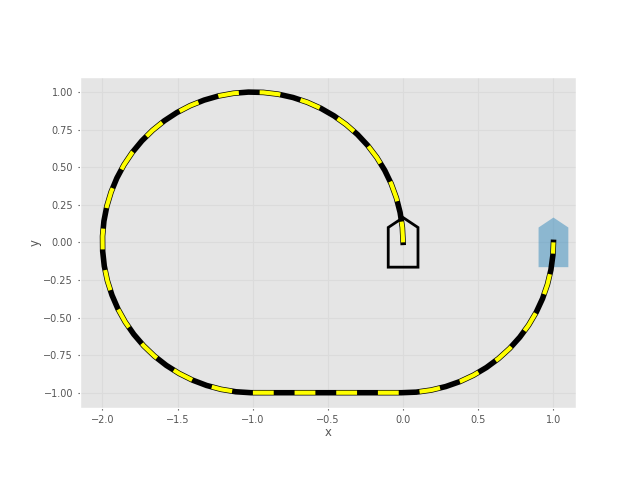

In [6]:
dubins.plot(path)

In [7]:
status

DubinsStatus(segments=['L', 'S', 'L'], length=7.283185307179586, seglengths=[4.71238898038469, 1.0, 1.5707963267948966])

<Axes3D: xlabel='x', ylabel='y', zlabel='$\\theta$'>

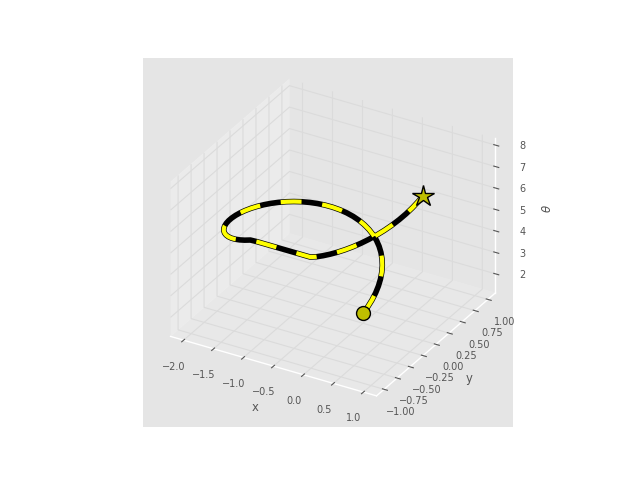

In [8]:
dubins.plot(path, configspace=True)

### Reeds-Shepp Path Planner

In [9]:
rs = ReedsSheppPlanner(curvature=1)
path, status = rs.query(qs, qg)
path.shape

(65, 3)

In [10]:
status

ReedsSheppStatus(segments=['R', 'L', 'R'], length=6.283185307179586, seglengths=[4.459708725242611, -0.5053605102841573, 1.3181160716528177], direction=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

<Axes: xlabel='x', ylabel='y'>

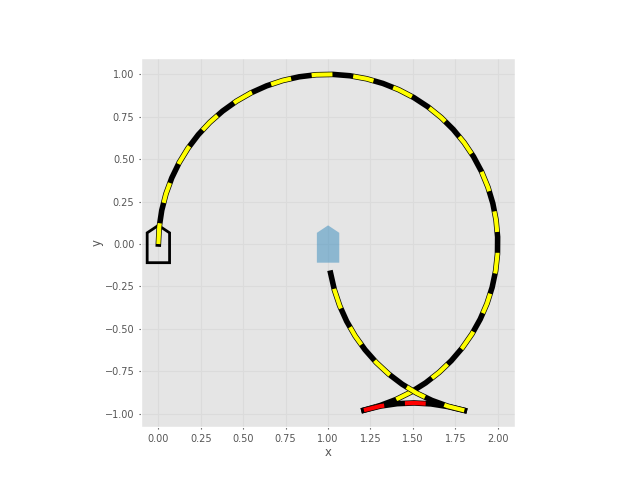

In [11]:
rs.plot(path, direction=status.direction)

<Axes3D: xlabel='x', ylabel='y', zlabel='$\\theta$'>

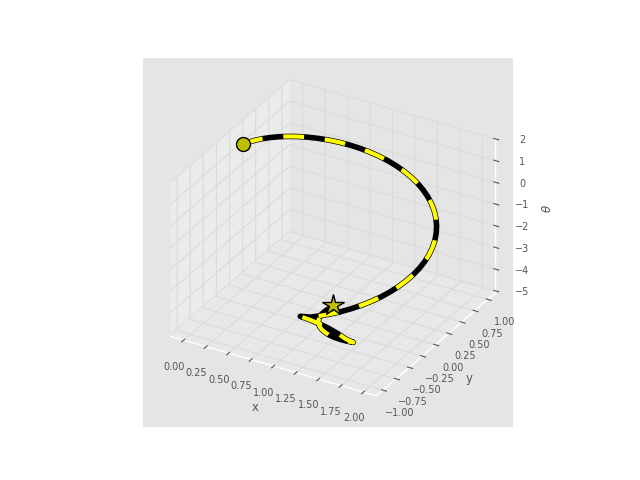

In [12]:
rs.plot(path, configspace=True)

### Lattice Planner